# Practical No. 5 — Use Pre-trained Models (VGG16/ResNet) to Classify Custom Images Using Fine-Tuning

**Source:** `DL-Practicals.docx` (Practical No. 5)  
**Platform:** Google Colab

## Aim
To implement Transfer Learning using pre-trained CNN models (VGG16/ResNet50) and fine-tune them for classifying custom image datasets.

## Objectives
- To understand Transfer Learning and Fine-Tuning.
- To use a pre-trained VGG16/ResNet50 model.
- To customize the output layer for a new classification problem.
- To train and evaluate the model on custom images.
- To classify unseen images using the fine-tuned model.

## Theory
### Transfer Learning
Transfer Learning is a machine learning technique where a model trained on a large dataset (such as ImageNet) is reused for a related task. Instead of training a CNN from scratch, we use pre-trained weights and modify the final layers according to our problem.

**Advantages:** Faster Training; Less Computational Cost; Better Accuracy; Requires Smaller Dataset.

### Fine-Tuning
Fine-Tuning refers to unfreezing some layers of a pre-trained model and retraining them on a custom dataset.

**Steps:** Load Pre-trained Model → Freeze Initial Layers → Add Custom Classification Layers → Train New Layers → Unfreeze Some Layers → Retrain with a Small Learning Rate.

### VGG16 Architecture
- 16 Weight Layers
- Uses 3×3 Convolution Filters
- Input Size: 224 × 224 × 3
- Trained on ImageNet Dataset

### ResNet50 Architecture
- 50 Layers Deep
- Uses Residual Connections
- Solves Vanishing Gradient Problem
- Higher Accuracy than VGG16 (as described in the practical document)

## Software Requirements
- Python 3.x
- TensorFlow/Keras
- NumPy
- Matplotlib
- OpenCV

Google Colab typically supplies most of these. The Python code below uses TensorFlow/Keras and NumPy. OpenCV and Matplotlib are requirements listed in the source document but are not directly used in its programs.

## Dataset Structure (from your Word document)
```text
dataset/
├── train/       ├── cats/   └── dogs/
├── validation/  ├── cats/   └── dogs/
└── test/        ├── cats/   └── dogs/
```

**Convenience setup (added for execution, not part of the Word practical):** Put your downloaded pictures in `downloaded_images/cats/` and `downloaded_images/dogs/` (or in one folder with filenames starting with `cat` or `dog`). The next cells copy and split them automatically into **70% train, 15% validation, and 15% test**. Your originals will remain untouched.

In **VS Code**, place `downloaded_images` alongside your notebook and open the `DL-Practicals` folder as the workspace. In **Google Colab**, upload the `downloaded_images` folder to `/content` (or use Google Drive by setting `BASE_DIR` accordingly). The original document does not include any image dataset, so you must provide your own images. Its example training numbers are illustrative only.


In [38]:
from pathlib import Path
import os

# Works in VS Code (Windows) and Google Colab.
# VS Code: make sure the notebook working directory contains downloaded_images/.
# Colab: uploaded images should be under /content/downloaded_images/.
BASE_DIR = Path.cwd()
if not (BASE_DIR / 'downloaded_images').is_dir() and (Path('/content') / 'downloaded_images').is_dir():
    BASE_DIR = Path('/content')

# If you keep the images somewhere else, set this explicitly, for example:
# BASE_DIR = Path(r'C:\Users\YourName\Desktop\DL-Practicals')
# In Google Drive, mount it, then set BASE_DIR to Path('/content/drive/MyDrive/DL-Practicals')

SOURCE_DIR = BASE_DIR / 'downloaded_images'
DATASET_DIR = BASE_DIR / 'dataset'
TRAIN_DIR = DATASET_DIR / 'train'
VALIDATION_DIR = DATASET_DIR / 'validation'
TEST_DIR = DATASET_DIR / 'test'
SAMPLE_IMAGE = BASE_DIR / 'sample.jpg'
print('Working folder:', BASE_DIR)
print('Source images:', SOURCE_DIR)
print('Organized dataset:', DATASET_DIR)


Working folder: d:\DL-Precticals
Source images: d:\DL-Precticals\downloaded_images
Organized dataset: d:\DL-Precticals\dataset


### Automatic dataset preparation (train / validation / test)
Run the cell below **once** after placing your downloaded photos in `downloaded_images`. No manual splitting is necessary.

In [39]:
from pathlib import Path
import random
import shutil

BASE_DIR = Path.cwd()

# Your actual folder locations
SOURCE_DIR = BASE_DIR / "dataset" / "downloaded_images"
DATASET_DIR = BASE_DIR / "dataset"

TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "validation"
TEST_DIR = DATASET_DIR / "test"

random.seed(42)

EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

categories = {
    "cats": "cats_set",
    "dogs": "dogs_set"
}

for category, source_name in categories.items():

    source_folder = SOURCE_DIR / source_name

    if not source_folder.exists():
        raise FileNotFoundError(
            f"Missing folder: {source_folder}"
        )

    images = [
        file for file in source_folder.rglob("*")
        if file.is_file() and file.suffix.lower() in EXTENSIONS
    ]

    random.shuffle(images)

    total = len(images)
    train_end = int(total * 0.70)
    val_end = train_end + int(total * 0.15)

    splits = {
        "train": images[:train_end],
        "validation": images[train_end:val_end],
        "test": images[val_end:]
    }

    for split_name, files in splits.items():

        destination = DATASET_DIR / split_name / category
        destination.mkdir(parents=True, exist_ok=True)

        # Remove old split images to prevent duplicates
        for old_file in destination.iterdir():
            if old_file.is_file():
                old_file.unlink()

        for index, image in enumerate(files):
            new_name = f"{category}_{index:05d}{image.suffix.lower()}"
            shutil.copy2(image, destination / new_name)

        print(f"{split_name}/{category}: {len(files)} images")

print("\nDataset organized successfully!")

train/cats: 350 images
validation/cats: 75 images
test/cats: 75 images
train/dogs: 350 images
validation/dogs: 75 images
test/dogs: 75 images

Dataset organized successfully!


## Algorithm
1. Import required libraries.
2. Load VGG16/ResNet50 pre-trained model.
3. Remove top classification layer.
4. Freeze pre-trained layers.
5. Add custom dense layers.
6. Compile the model.
7. Train on custom dataset.
8. Fine-tune selected layers.
9. Evaluate model accuracy.
10. Predict new images.

## Program 1: Fine-Tuning Using VGG16
The code below follows the document's VGG16 architecture, frozen base, image generator, and 5 training epochs. Model weights download from ImageNet on first use.

In [40]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.22.0-rc0


In [41]:
# Load VGG16 without its top classification layer
base_model_vgg = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
for layer in base_model_vgg.layers:
    layer.trainable = False

vgg_model = Sequential([
    base_model_vgg,
    Flatten(),
    Dense(256, activation='relu'),
    Dense(2, activation='softmax'),
])
vgg_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
vgg_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,137,986 (80.64 MB)

 Trainable params: 6,423,298 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [42]:
# Load the custom image dataset as described in the Word document
if not TRAIN_DIR.is_dir() or any(not list((TRAIN_DIR / cls).glob('*')) for cls in ('cats', 'dogs')):
    raise FileNotFoundError(f'Training images missing under {TRAIN_DIR}. Run the automatic dataset preparation cell above first.')

train_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_directory(
    str(TRAIN_DIR), target_size=(224, 224), batch_size=32,
    class_mode='categorical', shuffle=True,
)
print('Class indices:', train_generator.class_indices)

Found 700 images belonging to 2 classes.
Class indices: {'cats': 0, 'dogs': 1}


In [32]:
# Training (source document: 5 epochs)
vgg_history = vgg_model.fit(train_generator, epochs=5)

Epoch 1/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 76s 3s/step - accuracy: 0.6629 - loss: 1.6229
Epoch 2/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 113s 5s/step - accuracy: 0.8643 - loss: 0.3680
Epoch 3/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 87s 4s/step - accuracy: 0.9557 - loss: 0.1125
Epoch 4/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 75s 3s/step - accuracy: 0.9914 - loss: 0.0468
Epoch 5/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 75s 3s/step - accuracy: 0.9957 - loss: 0.0288


## Program 2: Fine-Tuning Using ResNet50
The Word document builds a ResNet50 model with global average pooling and a 2-class softmax head. It reuses the training generator prepared above.

In [33]:
base_model_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
for layer in base_model_resnet.layers:
    layer.trainable = False

x = base_model_resnet.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)

resnet_model = Model(inputs=base_model_resnet.input, outputs=predictions)
resnet_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
resnet_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_9[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,112,770 (91.98 MB)

 Trainable params: 525,058 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [34]:
resnet_history = resnet_model.fit(train_generator, epochs=5)

Epoch 1/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.5243 - loss: 0.7605
Epoch 2/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.5743 - loss: 0.6687
Epoch 3/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.5871 - loss: 0.6683
Epoch 4/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.5929 - loss: 0.6569
Epoch 5/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.6014 - loss: 0.6558


## Program 3: Classifying a Custom Image
The document uses `sample.jpg` at 224 × 224, scales pixels by 255, and predicts **Cat/Dog**. The source assumes class index 0 is Cat; `flow_from_directory()` assigns indices alphabetically, which should be checked before interpreting the result. This notebook uses the generator's class indices to report the correct label.

Selected Image: cats_00023.jpg
Actual Class: cats
1/1 ━━━━━━━━━━━━━━━━━━━━ 32s 32s/step

Prediction Probabilities: [[0.4200966 0.5799034]]
Predicted Class: dogs
Actual Class: cats


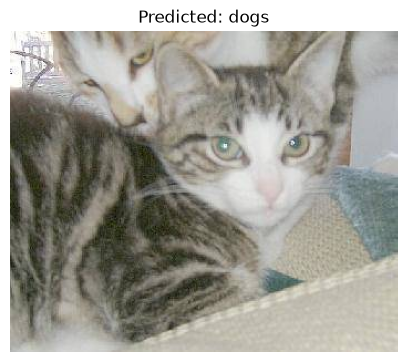

In [35]:
from pathlib import Path
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Use the test images prepared earlier
BASE_DIR = Path.cwd()
TEST_DIR = BASE_DIR / "dataset" / "test"

# Find all available images
test_images = [
    file for file in TEST_DIR.rglob("*")
    if file.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

if not test_images:
    raise FileNotFoundError(
        f"No test images found in {TEST_DIR}"
    )

# Select one random image
sample_image = random.choice(test_images)

print("Selected Image:", sample_image.name)
print("Actual Class:", sample_image.parent.name)

# Load and preprocess image
img = image.load_img(
    str(sample_image),
    target_size=(224, 224)
)

img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Predict using trained ResNet50 model
prediction = resnet_model.predict(img_array)

# Get class names
labels_by_index = {
    index: name
    for name, index in train_generator.class_indices.items()
}

predicted_index = int(np.argmax(prediction))
predicted_class = labels_by_index[predicted_index]

print("\nPrediction Probabilities:", prediction)
print("Predicted Class:", predicted_class)
print("Actual Class:", sample_image.parent.name)

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(image.load_img(str(sample_image)))
plt.title(f"Predicted: {predicted_class}")
plt.axis("off")
plt.show()

## Fine-Tuning Selected Layers
The Word document unfreezes the final 10 layers and retrains with a smaller learning rate (0.0001). This continues training the ResNet50 model used above.

In [36]:
# Unfreeze selected layers of the ResNet50 base
for layer in base_model_resnet.layers[-10:]:
    layer.trainable = True

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)
fine_tune_history = resnet_model.fit(train_generator, epochs=5)

Epoch 1/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.5943 - loss: 0.7180
Epoch 2/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.6971 - loss: 0.5571
Epoch 3/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.7400 - loss: 0.5061
Epoch 4/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.7529 - loss: 0.4887
Epoch 5/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.7971 - loss: 0.4481


## Evaluation
The algorithm includes evaluating model accuracy. The document gives training examples but **no separate evaluation program**; this optional cell evaluates on `dataset/test` if that folder contains class images. It does not manufacture accuracy results.

In [37]:
if TEST_DIR.is_dir() and any((TEST_DIR / c).is_dir() for c in ('cats','dogs')):
    test_generator = ImageDataGenerator(rescale=1./255).flow_from_directory(
        str(TEST_DIR), target_size=(224, 224), batch_size=32,
        class_mode='categorical', shuffle=False,
    )
    if test_generator.samples:
        test_loss, test_accuracy = resnet_model.evaluate(test_generator)
        print('Test Loss:', test_loss)
        print('Test Accuracy:', test_accuracy)
    else:
        print('Test folders are empty; evaluation not performed.')
else:
    print('No test dataset found; upload images under dataset/test/cats and dataset/test/dogs to evaluate.')

Found 150 images belonging to 2 classes.
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.6200 - loss: 0.6501
Test Loss: 0.6500982642173767
Test Accuracy: 0.6200000047683716


## Result (from the Word document)
A pre-trained CNN model (VGG16/ResNet50) was successfully implemented using Transfer Learning and Fine-Tuning techniques. The model achieved high classification accuracy on custom image datasets and successfully classified unseen images.

*Note:* This result is quoted from the provided practical; verify actual results by running all cells with your dataset.